# Structural Graph Features for AML Detection — Presentation Notebook

**Author:** Ilia Jakhaia

This presentation notebook imports metadata and feature definitions from `src/aml_graph` and loads precomputed tables and figures from `outputs/`. All data verification, subgraph sampling, feature extraction, model training, calibration, and diagnostics are executed via `make all` (or `python -m aml_graph ...`).

> For the archived pre-refactor 81-cell monolithic notebook, see `notebooks/legacy/AML_Graph_Structure_Transfer_legacy.ipynb`.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path('src').resolve()))
from aml_graph import __version__
from aml_graph.config import config_hashes
from aml_graph.features import FEATURES, SIZE_COLS

OUT = Path('outputs')
EXT = OUT / 'research_extension'
print(f'aml_graph v{__version__} | {len(FEATURES)} structural features | size baseline: {SIZE_COLS}')
print('Config SHA-256:', config_hashes(Path('configs'))['combined_sha256'])

aml_graph v0.1.0 | 14 structural features | size baseline: ['n_nodes', 'n_edges']
Config SHA-256: 109a4ac2cee666f8fff63ec144b0cbbacfb652dd9e9000d58f17ff08b640da9a


## 1. Dataset & Subgraph Construction Summary

Summary statistics recorded by the data-cleaning and subgraph-building pipeline (`outputs/prep_log.json`).

In [2]:
prep = json.loads((OUT / 'prep_log.json').read_text(encoding='utf-8'))
summary_rows = [
    {'Domain': 'IBM AML HI-Small', 'Raw Transactions / Edges': prep['ibm']['raw_rows'],
     'Subgraphs': prep['subgraphs']['ibm_final_subgraphs'],
     'Positive Rate': prep['subgraphs']['ibm_prevalence']},
    {'Domain': 'Elliptic2', 'Raw Transactions / Edges': prep['elliptic2']['edge_rows'],
     'Subgraphs': prep['subgraphs']['elliptic2_final_subgraphs'],
     'Positive Rate': prep['subgraphs']['elliptic2_prevalence']},
]
display(pd.DataFrame(summary_rows))

,Domain,Raw Transactions / Edges,Subgraphs,Positive Rate
0,IBM AML HI-Small,5078345,7770,0.0476
1,Elliptic2,367137,121810,0.0227


## 2. Phase 1 Refactor Numerical Regression Check

Comparison between the legacy monolithic notebook outputs and the refactored `aml_graph` package across every within-domain (`IBM → IBM`, `Elliptic2 → Elliptic2`) and cross-domain (`IBM → Elliptic2`, `Elliptic2 → IBM`) evaluation row (`outputs/phase1_verify/regression.csv`).

In [3]:
reg = pd.read_csv(OUT / 'phase1_verify' / 'regression.csv')
reg_summary = (
    reg.groupby(['suite', 'model'], as_index=False)['abs_diff']
    .agg(comparisons='count', max_abs_diff='max', median_abs_diff='median')
)
display(reg_summary)

,suite,model,comparisons,max_abs_diff,median_abs_diff
0,legacy_3seed,GradBoosting,192,0.000000e+00,0.0
1,legacy_3seed,LogReg,192,5.357436e-09,0.0
2,legacy_3seed,RandomForest,192,6.666667e-02,0.0
3,legacy_3seed,SizeOnly,192,0.000000e+00,0.0
4,unit4_5_holdout,ExtraTrees,104,2.220446e-16,0.0
5,unit4_5_holdout,GradBoosting,156,0.000000e+00,0.0
6,unit4_5_holdout,LogReg,156,4.812785e-08,0.0
7,unit4_5_holdout,RandomForest,156,1.190476e-02,0.0


## 3. Within-Domain & Cross-Domain Holdout Results (Unit 4/5 Tuned & Calibrated)

Outer-test evaluation with hyperparameters, Platt probability calibration, and F1 operating thresholds selected strictly on source validation splits (`outputs/unit5_holdout_comparison.csv`).

,source,target,model,variant,prevalence,pr_auc,pr_auc_ci95_lo,pr_auc_ci95_hi,lift,roc_auc,f1,brier
2,ibm,ibm,LogReg,tuned,0.0498,0.5677,0.4643,0.6677,11.3944,0.8769,0.4848,0.1159
3,ibm,elliptic2,LogReg,tuned,0.0227,0.0223,0.0204,0.0243,0.9851,0.4919,0.0413,0.2270
4,ibm,ibm,LogReg,tuned_calibrated,0.0498,0.5677,0.4643,0.6677,11.3944,0.8769,0.4848,0.0315
5,ibm,elliptic2,LogReg,tuned_calibrated,0.0227,0.0223,0.0203,0.0242,0.9824,0.4919,0.0413,0.0922
8,ibm,ibm,RandomForest,tuned,0.0498,0.5638,0.4581,0.6712,11.3159,0.8751,0.5638,0.0880
9,ibm,elliptic2,RandomForest,tuned,0.0227,0.0230,0.0210,0.0251,1.0148,0.4981,0.0399,0.2150
10,ibm,ibm,RandomForest,tuned_calibrated,0.0498,0.5638,0.4581,0.6712,11.3159,0.8751,0.5638,0.0290
11,ibm,elliptic2,RandomForest,tuned_calibrated,0.0227,0.0230,0.0210,0.0251,1.0148,0.4981,0.0399,0.0589
14,ibm,ibm,GradBoosting,tuned,0.0498,0.6218,0.5227,0.7199,12.4797,0.8884,0.6116,0.0990
15,ibm,elliptic2,GradBoosting,tuned,0.0227,0.0227,0.0209,0.0247,0.9997,0.4982,0.0402,0.2470


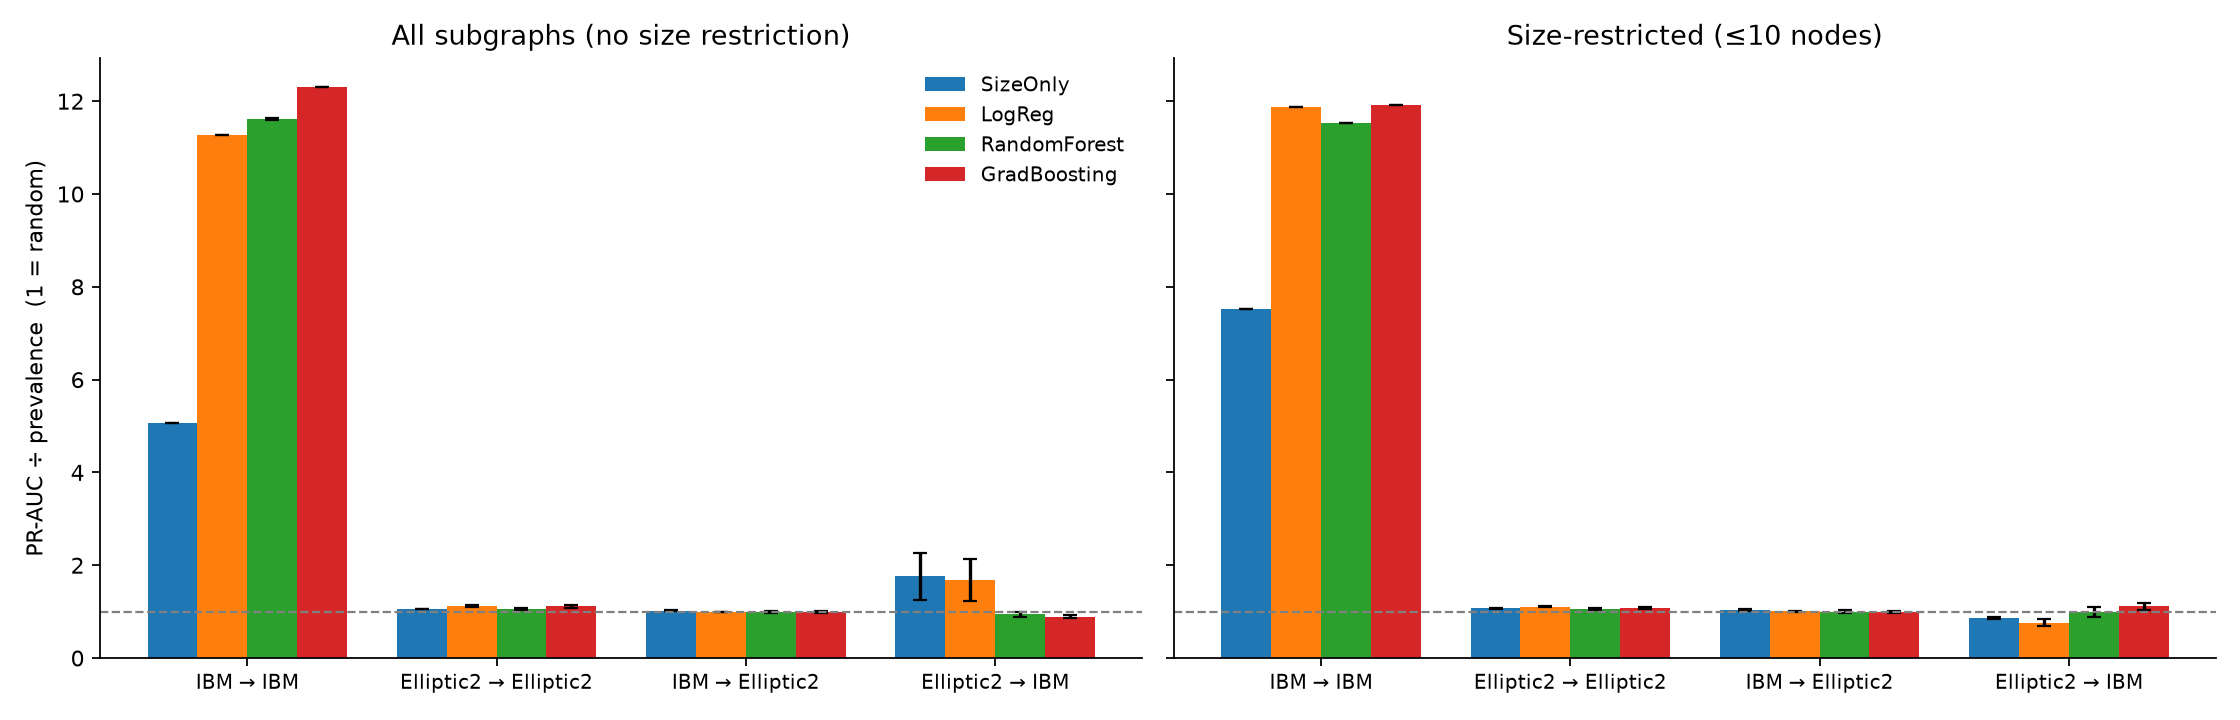

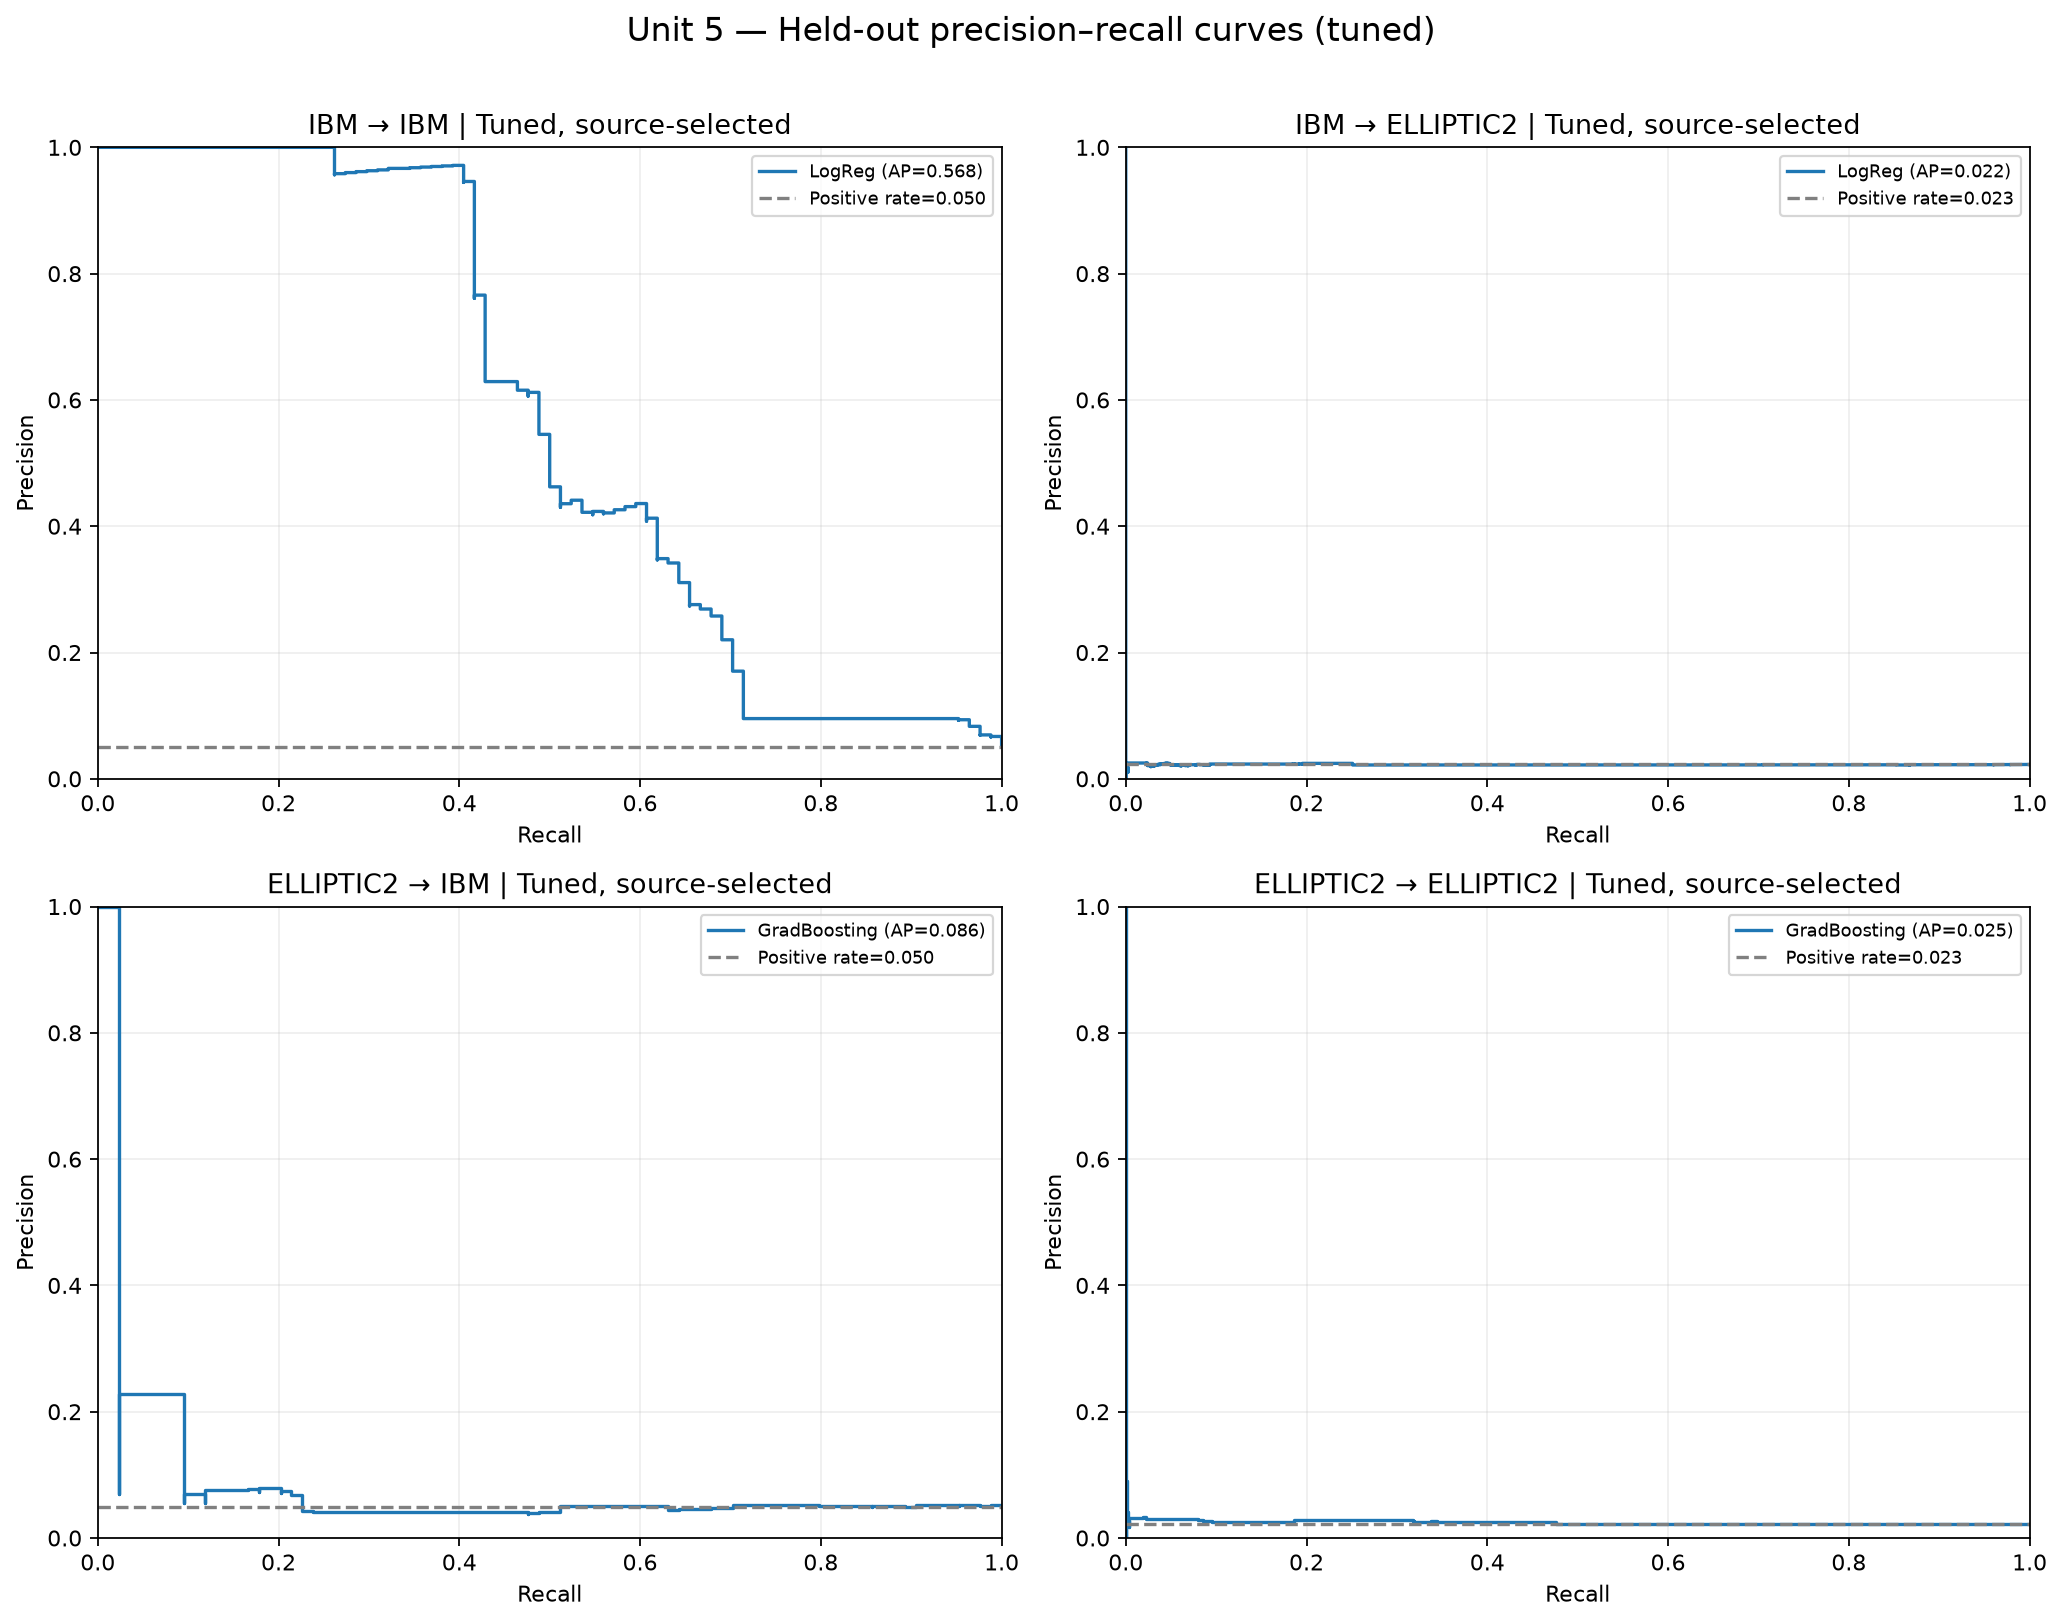

In [4]:
u5 = pd.read_csv(OUT / 'unit5_holdout_comparison.csv')
cols = ['source', 'target', 'model', 'variant', 'prevalence', 'pr_auc',
        'pr_auc_ci95_lo', 'pr_auc_ci95_hi', 'lift', 'roc_auc', 'f1', 'brier']
display(u5[u5['variant'].isin(['tuned', 'tuned_calibrated'])][cols].round(4))
display(Image(filename=str(OUT / 'results_lift.png')))
display(Image(filename=str(OUT / 'unit5_tuned_precision_recall_curves.png')))

## 4. Robustness Extensions, Domain Shift & Typology Recall

Key diagnostic tables and plots from `outputs/research_extension/`: common-BFS candidate sensitivity, account-disjoint retraining, domain-shift KS statistics, IBM activity features, and per-typology recall.

--- Common-BFS Sensitivity (2,500 candidates) ---


,model,validation_AP,prevalence,AP,AP_lift,ROC_AUC,F1,selected_by_validation
0,GradBoosting,0.5380,0.6623,0.7258,1.0959,0.6061,0.8006,True
1,LogReg,0.5323,0.6623,0.7158,1.0808,0.5795,0.7969,False
2,RandomForest,0.5267,0.6623,0.7219,1.0900,0.6062,0.7981,False
3,SizeOnly,0.4220,0.6623,0.6499,0.9812,0.4782,0.7969,False


--- Account-Disjoint Retrain ---


,split,fit_n,val_n,status,n,positives,prevalence,AP,AP_lift,ROC_AUC,precision,recall,F1,TN,FP,FN,TP
0,account_disjoint_retrain,6877,437,ok,365,6,0.0164,0.6735,40.9734,0.7611,1.0,0.6667,0.8,359,0,2,4


--- IBM Activity Feature Experiment (14 vs 20 features) ---


,family,features,validation_AP,AP,AP_lift,ROC_AUC,F1,selected_by_validation
0,validation_selected_original_family,augmented_20,0.9530,0.8602,17.2645,0.9792,0.7972,True
1,ExtraTrees,augmented_20,0.8841,0.7952,15.9613,0.9832,0.7463,False
2,validation_selected_original_family,original_14,0.7692,0.5677,11.3944,0.8769,0.4848,False
3,ExtraTrees,original_14,0.6942,0.5993,12.0290,0.8782,0.5763,False


--- IBM Laundering Typology Recall Breakdown ---


,pattern,test_count,median_nodes,recall_14feat,recall_20feat
0,CYCLE,8,8.0,1.0000,1.0000
1,SCATTER-GATHER,11,8.0,0.9091,0.9091
2,STACK,8,2.5,0.8750,1.0000
3,FAN-IN,12,10.0,0.7500,0.7500
4,GATHER-SCATTER,12,13.5,0.5000,0.8333
5,RANDOM,11,4.0,0.4545,0.4545
6,BIPARTITE,14,2.0,0.2143,0.2143
7,FAN-OUT,8,11.5,0.0000,0.5000


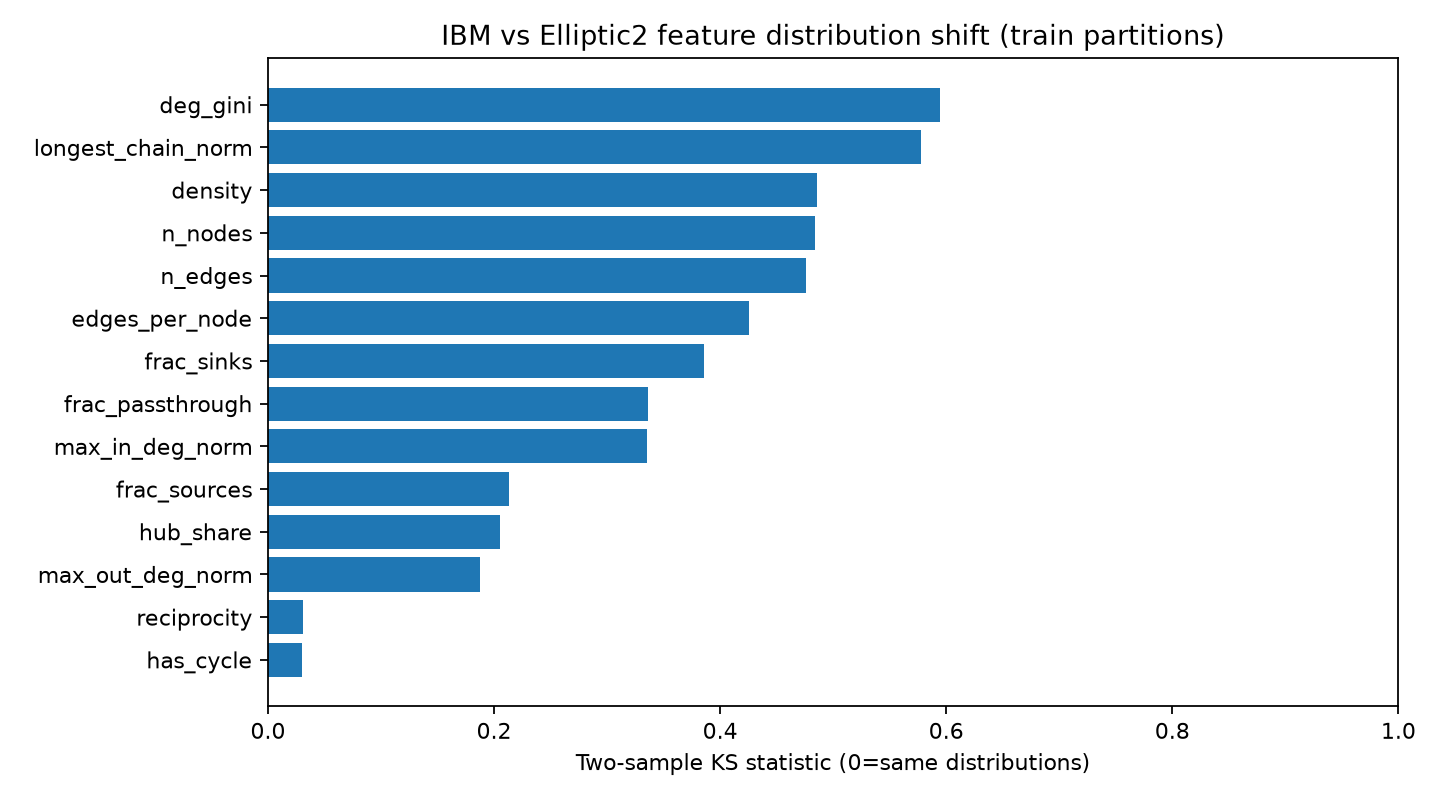

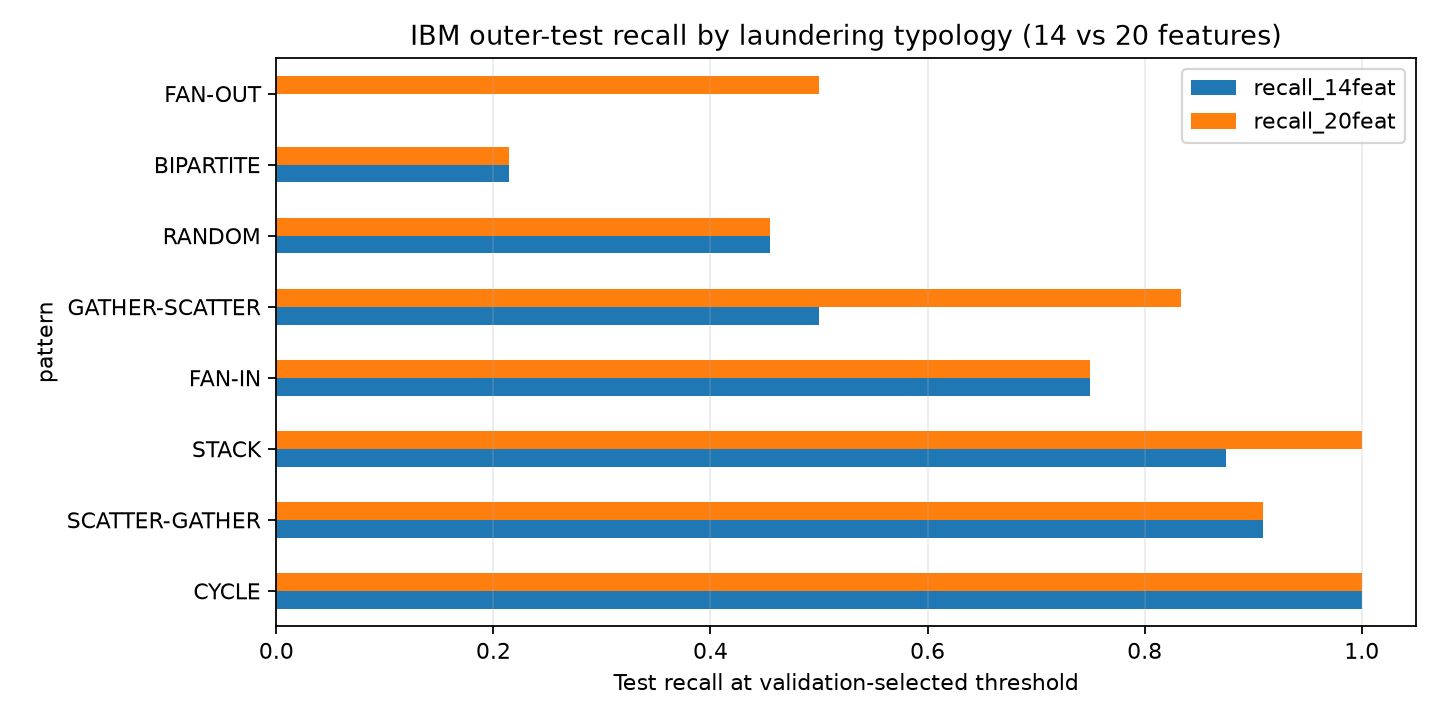

In [5]:
print('--- Common-BFS Sensitivity (2,500 candidates) ---')
display(pd.read_csv(EXT / 'common_bfs_model_results.csv')[[
    'model', 'validation_AP', 'prevalence', 'AP', 'AP_lift', 'ROC_AUC', 'F1', 'selected_by_validation'
]].round(4))

print('--- Account-Disjoint Retrain ---')
display(pd.read_csv(EXT / 'account_disjoint_retrain.csv').round(4))

print('--- IBM Activity Feature Experiment (14 vs 20 features) ---')
display(pd.read_csv(EXT / 'IBM_activity_feature_experiment.csv')[[
    'family', 'features', 'validation_AP', 'AP', 'AP_lift', 'ROC_AUC', 'F1', 'selected_by_validation'
]].round(4))

print('--- IBM Laundering Typology Recall Breakdown ---')
display(pd.read_csv(EXT / 'typology_recall_breakdown.csv').round(4))
display(Image(filename=str(EXT / 'domain_shift_KS.png')))
display(Image(filename=str(EXT / 'typology_recall_breakdown.png')))

## 5. Known Methodological Confounds Addressed Next (Phase 2)

1. **Construction confound:** Legacy IBM positives come from documented laundering attempts while negatives come from licit BFS neighborhoods.
2. **Window leak (`tests/test_window_leak_xfail.py`):** Legacy positive windows clamp `[t0, t1]` to attempt endpoints whereas negative windows sample random `[t0, t0 + dur]`.
3. **Single chronological split & small stress subsets:** Addressed in Phase 2 via rolling-origin temporal folds and connected-component account-group splits.